# IS403 - Walmart M5: Stationarity and Correlation Diagnostics

Examine the audited Level 1 **Train** series before specifying ARIMA and
SARIMA candidates. Only `train.csv` is read. Validation and Test remain outside
this diagnostic step. Run all cells on Kaggle CPU with the existing processed
dataset. No path changes, package installation, or Internet access are needed
in the standard Kaggle environment.

The workflow follows the project's Box-Jenkins plan and Chapter 5:
inspect the original series, compare ordinary and weekly differences, run
ADF/KPSS, then inspect ACF/PACF. These diagnostics suggest candidate orders;
they do not replace Validation forecasting or residual diagnostics.

In [1]:
from pathlib import Path
from importlib import metadata
from inspect import signature
from datetime import datetime, timezone
from time import perf_counter
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib
import json
import platform
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

DATA_DIR = None
OUTPUT_DIR = None

SEED = 42
ALPHA = 0.05
MAX_LAG = 28
SEASON_LENGTH = 7
random.seed(SEED)
np.random.seed(SEED)
RUN_STARTED = perf_counter()

## 1. Verify and load Train

The fingerprint covers all 14 columns, not only sales. The input must contain
the original 1,885 consecutive days ending on 27 March 2016. No missing days
are filled, no outliers are removed, and no transformation uses future values.

In [2]:
EXPECTED_COLUMNS = ['d', 'date', 'total_sales', 'weekday', 'wday_iso', 'month',
                    'year', 'event_name_1', 'event_type_1', 'event_name_2',
                    'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
REFERENCE_SHA256 = 'dcb9407590b16f6b975a1647c1c20f3cb932bc78dd75c1637f94d313c599d271'


def require(condition, message):
    if not condition:
        raise ValueError(message)


def find_data_directory(override=None):
    if override is not None:
        directory = Path(override).expanduser().resolve()
        require((directory / 'train.csv').is_file(), 'train.csv was not found.')
        return directory
    candidates = set()
    for directory in [Path.cwd(), Path.cwd() / 'dataset',
                      Path.cwd() / '02_Data' / 'processed']:
        if (directory / 'train.csv').is_file():
            candidates.add(directory.resolve())
    root = Path('/kaggle/input')
    if root.is_dir():
        candidates.update(path.parent.resolve() for path in root.rglob('train.csv'))
    require(bool(candidates), 'Attach the processed dataset containing train.csv.')
    require(len(candidates) == 1,
            'Multiple train.csv files found. Set DATA_DIR to the intended folder.')
    return candidates.pop()


data_dir = find_data_directory(DATA_DIR)
output_dir = Path(OUTPUT_DIR) if OUTPUT_DIR is not None else (
    Path('/kaggle/working') if Path('/kaggle/working').is_dir()
    else Path.cwd() / 'stationarity_output'
)
train = pd.read_csv(data_dir / 'train.csv', keep_default_na=False)
require(list(train.columns) == EXPECTED_COLUMNS, 'Incorrect column names or order.')
canonical_csv = train.to_csv(index=False, lineterminator='\n')
fingerprint = hashlib.sha256(canonical_csv.encode('utf-8')).hexdigest()
require(fingerprint == REFERENCE_SHA256, 'Train differs from the audited handoff.')
require(len(train) == 1885, 'Expected 1,885 training rows.')
require(train['d'].tolist() == [f'd_{day}' for day in range(1, 1886)],
        'Incorrect training day IDs.')
dates = pd.to_datetime(train['date'], format='%Y-%m-%d', errors='raise')
require(dates.tolist() == pd.date_range('2011-01-29', periods=1885).tolist(),
        'Train must contain consecutive daily dates.')
sales = train['total_sales'].to_numpy(dtype=np.float64)
require(np.isfinite(sales).all() and (sales >= 0).all(), 'Invalid training sales.')
y = pd.Series(sales, index=pd.DatetimeIndex(dates, name='date'), name='total_sales')
print(f'Data: {data_dir}')
print(f'Train: {len(y):,} days, {y.index[0].date()} to {y.index[-1].date()}')
print('PASS: audited Train verified; Validation and Test have not been read.')

Data: /kaggle/input/datasets/nhntrnc/is403-m5-level-1
Train: 1,885 days, 2011-01-29 to 2016-03-27
PASS: audited Train verified; Validation and Test have not been read.


## 2. Compare four transformations

| Series | Definition | Ordinary order d | Seasonal order D |
|---|---|---:|---:|
| Original | $y_t$ | 0 | 0 |
| First difference | $y_t-y_{t-1}$ | 1 | 0 |
| Weekly difference | $y_t-y_{t-7}$ | 0 | 1 |
| First + weekly difference | $(1-B)(1-B^7)y_t$ | 1 | 1 |

Weekly differencing is a candidate to investigate, not a default requirement.
The plots show the full Train period and its final 112 days. Negative values
in a differenced series are valid changes in sales and are not clipped.

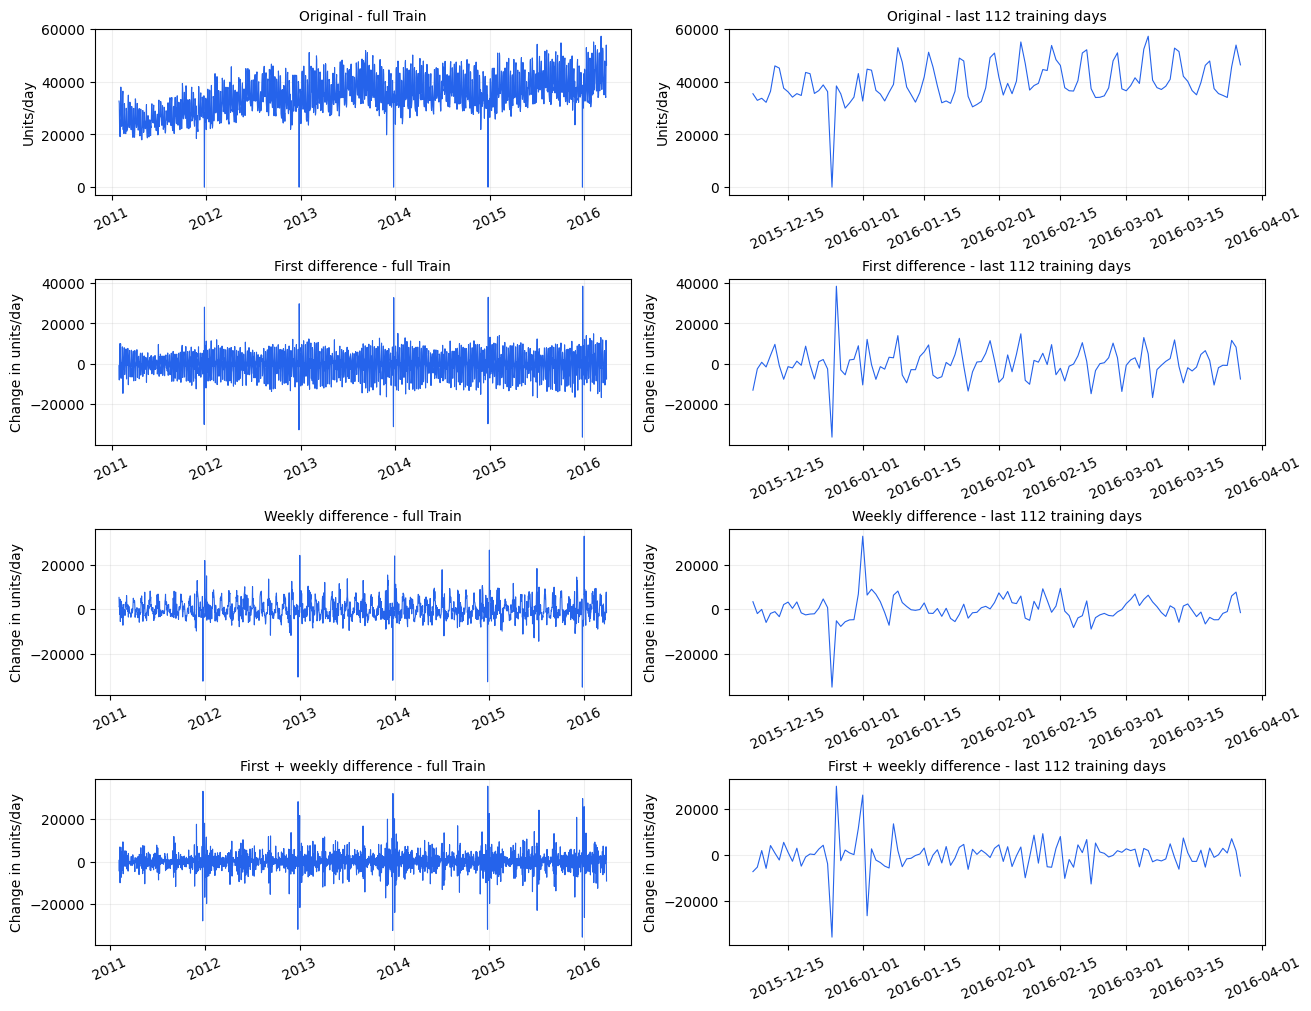

In [3]:
transformations = [
    {'series': 'original', 'label': 'Original', 'd': 0, 'D': 0},
    {'series': 'first_difference', 'label': 'First difference', 'd': 1, 'D': 0},
    {'series': 'weekly_difference', 'label': 'Weekly difference', 'd': 0, 'D': 1},
    {'series': 'first_weekly_difference', 'label': 'First + weekly difference',
     'd': 1, 'D': 1},
]
series_by_name = {}
for item in transformations:
    transformed = y.copy()
    if item['d']:
        transformed = transformed.diff()
    if item['D']:
        transformed = transformed.diff(SEASON_LENGTH)
    transformed = transformed.dropna()
    require(len(transformed) == len(y) - item['d'] - SEASON_LENGTH * item['D'],
            'Unexpected number of observations after differencing.')
    require(np.isfinite(transformed.to_numpy()).all(), 'Non-finite transformed values.')
    series_by_name[item['series']] = transformed

fig_series, axes = plt.subplots(4, 2, figsize=(13, 10), layout='constrained')
for row, item in enumerate(transformations):
    values = series_by_name[item['series']]
    for col, subset in enumerate([values, values.iloc[-112:]]):
        ax = axes[row, col]
        ax.plot(subset.index, subset.to_numpy(), color='#2563eb', linewidth=0.8)
        period = 'full Train' if col == 0 else 'last 112 training days'
        ax.set_title(f"{item['label']} - {period}", fontsize=10)
        ax.set_ylabel('Units/day' if item['series'] == 'original' else 'Change in units/day')
        ax.grid(alpha=0.2)
        ax.tick_params(axis='x', labelrotation=25)
plt.show()
plt.close(fig_series)

## 3. Run paired ADF and KPSS tests

ADF tests the null of a unit root. KPSS tests the null of stationarity.
At the 5% level, ADF rejection together with KPSS non-rejection supports
stationarity under the chosen deterministic specification; it does not prove it.

- `c`: constant only; assess stationarity around a level.
- `ct`: constant and linear trend; assess stationarity around a deterministic trend.

Both specifications are reported as a sensitivity check. ADF uses AIC lag
selection within an explicit sample-size-based maximum; KPSS uses automatic
bandwidth selection. KPSS returns table boundaries for very small or large
p-values. Inequalities and the original warnings are retained in the results.
Conflicting tests, structural changes, outliers, and negative short-lag
correlations must be considered before choosing differencing orders.

In [4]:
def tuple_options(function):
    return {'result_object': False} if 'result_object' in signature(function).parameters else {}


test_rows = []
for item in transformations:
    values = series_by_name[item['series']].to_numpy()
    maxlag = min(int(np.ceil(12 * (len(values) / 100) ** 0.25)), len(values) // 2 - 3)
    for regression in ['c', 'ct']:
        with warnings.catch_warnings(record=True) as adf_warnings:
            warnings.simplefilter('always')
            adf_result = adfuller(values, maxlag=maxlag, regression=regression,
                                  autolag='AIC', **tuple_options(adfuller))
        with warnings.catch_warnings(record=True) as kpss_warnings:
            warnings.simplefilter('always')
            kpss_result = kpss(values, regression=regression, nlags='auto',
                               **tuple_options(kpss))
        adf_stat, adf_p, adf_lags, adf_nobs, adf_crit, adf_ic = adf_result
        kpss_stat, kpss_p, kpss_lags, kpss_crit = kpss_result
        kpss_messages = ' | '.join(str(w.message).strip() for w in kpss_warnings)
        adf_reject = bool(adf_p < ALPHA)
        kpss_reject = bool(kpss_p < ALPHA)
        if adf_reject and not kpss_reject:
            evidence = 'Supports level stationarity' if regression == 'c' else 'Supports trend stationarity'
        elif not adf_reject and kpss_reject:
            evidence = 'Supports nonstationarity'
        else:
            evidence = 'Mixed or inconclusive evidence'
        if 'greater than' in kpss_messages:
            kpss_display = f'> {kpss_p:g}'
        elif 'smaller than' in kpss_messages:
            kpss_display = f'< {kpss_p:g}'
        else:
            kpss_display = f'{kpss_p:.6g}'
        test_rows.append({
            **{key: item[key] for key in ['series', 'd', 'D']},
            'regression': regression, 'observations': len(values),
            'first_date': series_by_name[item['series']].index[0].strftime('%Y-%m-%d'),
            'last_date': y.index[-1].strftime('%Y-%m-%d'),
            'adf_statistic': float(adf_stat), 'adf_pvalue': float(adf_p),
            'adf_maxlag': maxlag, 'adf_usedlag': int(adf_lags),
            'adf_nobs': int(adf_nobs), 'adf_aic': float(adf_ic),
            'adf_critical_5pct': float(adf_crit['5%']),
            'adf_reject_unit_root': adf_reject,
            'adf_warnings': ' | '.join(str(w.message).strip() for w in adf_warnings),
            'kpss_statistic': float(kpss_stat), 'kpss_pvalue_boundary': float(kpss_p),
            'kpss_pvalue_display': kpss_display, 'kpss_usedlag': int(kpss_lags),
            'kpss_critical_5pct': float(kpss_crit['5%']),
            'kpss_reject_stationarity': kpss_reject,
            'kpss_warnings': kpss_messages, 'interpretation': evidence,
        })
stationarity_tests = pd.DataFrame(test_rows)
require(len(stationarity_tests) == 8, 'Expected eight paired test results.')
print(stationarity_tests[['series', 'regression', 'observations', 'adf_pvalue',
                          'kpss_pvalue_display', 'interpretation']]
      .to_string(index=False, float_format=lambda value: f'{value:.6g}'))
print('KPSS p-value limits and warnings are recorded, not treated as execution errors.')

                 series regression  observations  adf_pvalue kpss_pvalue_display              interpretation
               original          c          1885    0.489205              < 0.01    Supports nonstationarity
               original         ct          1885    0.163687              < 0.01    Supports nonstationarity
       first_difference          c          1884           0               > 0.1 Supports level stationarity
       first_difference         ct          1884           0               > 0.1 Supports trend stationarity
      weekly_difference          c          1878           0               > 0.1 Supports level stationarity
      weekly_difference         ct          1878           0               > 0.1 Supports trend stationarity
first_weekly_difference          c          1877           0               > 0.1 Supports level stationarity
first_weekly_difference         ct          1877           0               > 0.1 Supports trend stationarity
KPSS p-value limits

## 4. Inspect ACF and PACF through lag 28

ACF measures correlation with past observations; PACF controls for intermediate
lags. Repeated structure at multiples of seven supports investigating a weekly
component. A sharp negative correlation after differencing can also warn of
overdifferencing. Patterns suggest a small candidate space, not a unique model.

Shaded bands are approximate pointwise 95% intervals, not simultaneous bands
or formal proof of seasonality. ACF/PACF on the original, possibly nonstationary
series are descriptive. Interpret AR/MA orders on suitable transformed series.

                 series  lag     acf    pacf
               original    1  0.6699  0.6699
               original    7  0.8032  0.4232
               original   14  0.7314  0.1807
               original   21  0.7462  0.2254
               original   28  0.8136  0.2161
       first_difference    1  0.0561  0.0561
       first_difference    7  0.6437  0.1646
       first_difference   14  0.6145  0.0966
       first_difference   21  0.6106 -0.0207
       first_difference   28  0.6109 -0.0742
      weekly_difference    1  0.3941  0.3941
      weekly_difference    7 -0.3218 -0.3737
      weekly_difference   14 -0.2340 -0.3343
      weekly_difference   21 -0.1399 -0.3090
      weekly_difference   28  0.3110 -0.0552
first_weekly_difference    1 -0.3882 -0.3882
first_weekly_difference    7 -0.4584 -0.3732
first_weekly_difference   14 -0.0398 -0.2217
first_weekly_difference   21 -0.0011 -0.1987
first_weekly_difference   28  0.0364 -0.2064


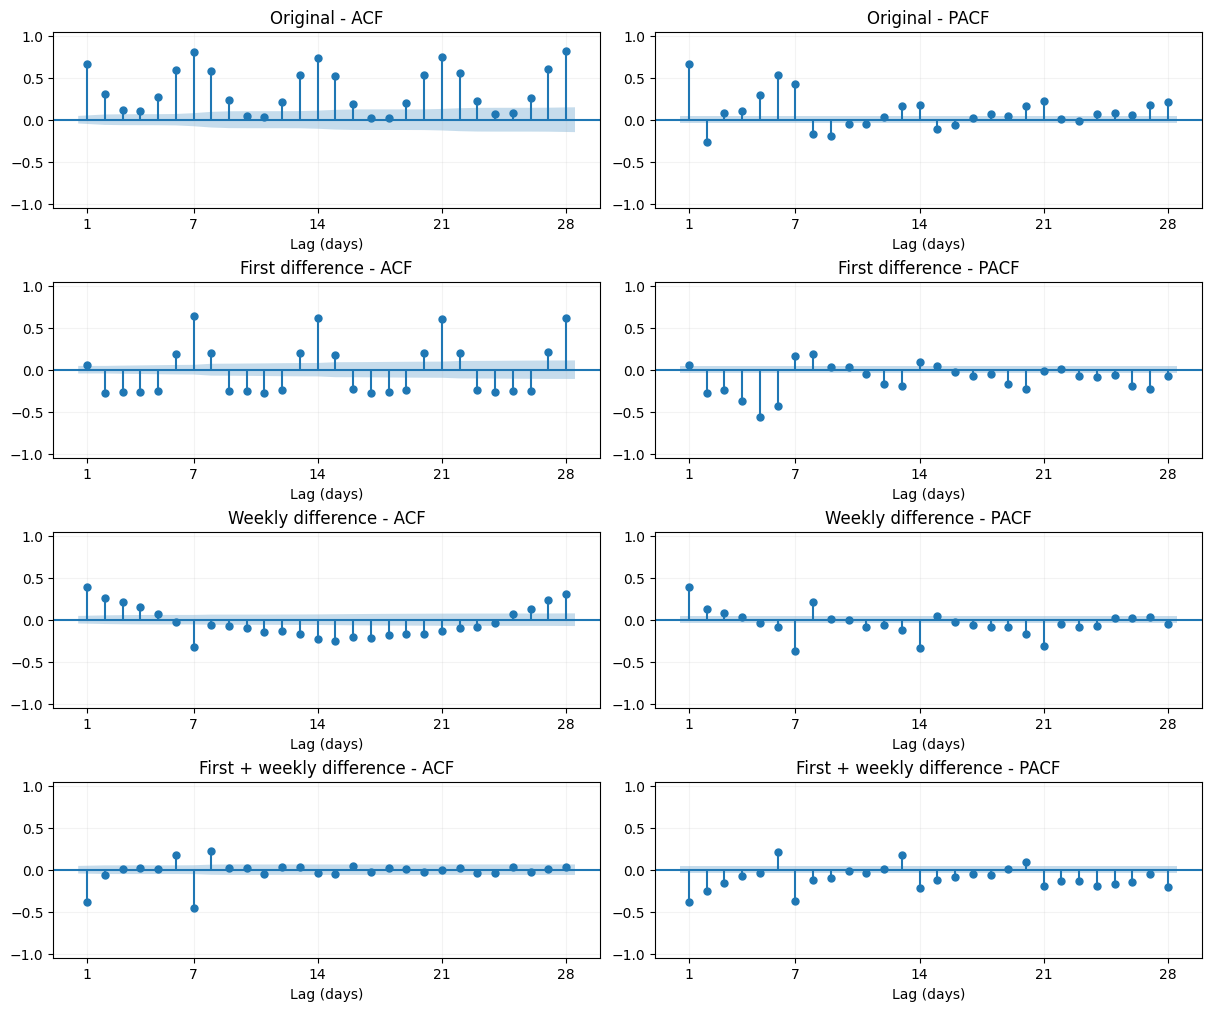

In [5]:
correlation_rows = []
fig_correlations, axes = plt.subplots(4, 2, figsize=(12, 10), layout='constrained')
for row, item in enumerate(transformations):
    values = series_by_name[item['series']].to_numpy()
    acf_values, acf_intervals = acf(values, nlags=MAX_LAG, fft=True, alpha=ALPHA,
                                     **tuple_options(acf))
    pacf_values, pacf_intervals = pacf(values, nlags=MAX_LAG, method='ywm', alpha=ALPHA,
                                        **tuple_options(pacf))
    plot_acf(values, lags=MAX_LAG, fft=True, alpha=ALPHA, zero=False,
             ax=axes[row, 0], title=f"{item['label']} - ACF")
    plot_pacf(values, lags=MAX_LAG, method='ywm', alpha=ALPHA, zero=False,
              ax=axes[row, 1], title=f"{item['label']} - PACF")
    for ax in axes[row]:
        ax.set_xlabel('Lag (days)')
        ax.set_ylim(-1.05, 1.05)
        ax.set_xticks([1, 7, 14, 21, 28])
        ax.grid(alpha=0.15)
    for lag in range(1, MAX_LAG + 1):
        correlation_rows.append({
            'series': item['series'], 'd': item['d'], 'D': item['D'], 'lag': lag,
            'acf': float(acf_values[lag]),
            'acf_lower_95': float(acf_intervals[lag, 0]),
            'acf_upper_95': float(acf_intervals[lag, 1]),
            'pacf': float(pacf_values[lag]),
            'pacf_lower_95': float(pacf_intervals[lag, 0]),
            'pacf_upper_95': float(pacf_intervals[lag, 1]),
        })
correlations = pd.DataFrame(correlation_rows)
require(len(correlations) == 112, 'Expected 112 correlation rows.')
print(correlations[correlations['lag'].isin([1, 7, 14, 21, 28])]
      [['series', 'lag', 'acf', 'pacf']].round(4).to_string(index=False))
plt.show()
plt.close(fig_correlations)

## 5. Save the diagnostic evidence

The bundle contains two tables, two 300 DPI figures, and one run report.
`PASS` means the data and diagnostic outputs passed consistency checks; it
does not mean every series is stationary or any forecasting model is adequate.

Next, use this evidence to justify a bounded ARIMA/SARIMA search. Compare
candidates on the same 28-day development windows as the baselines, record
AIC/BIC, and inspect fitted residuals with Ljung-Box and residual ACF.
Keep Test locked throughout model selection.

In [6]:
table_dir = output_dir / '04_Outputs_and_Artifacts' / 'table'
figure_dir = output_dir / '04_Outputs_and_Artifacts' / 'figures'
for directory in [table_dir, figure_dir]:
    directory.mkdir(parents=True, exist_ok=True)
tests_path = table_dir / 'stationarity_tests.csv'
correlations_path = table_dir / 'stationarity_acf_pacf.csv'
series_path = figure_dir / 'stationarity_transformations.png'
acf_path = figure_dir / 'stationarity_acf_pacf.png'
report_path = output_dir / '04_Outputs_and_Artifacts' / 'stationarity_run_report.json'
stationarity_tests.to_csv(tests_path, index=False, float_format='%.12g')
correlations.to_csv(correlations_path, index=False, float_format='%.12g')
fig_series.savefig(series_path, dpi=300, bbox_inches='tight')
fig_correlations.savefig(acf_path, dpi=300, bbox_inches='tight')
report = {
    'status': 'PASS', 'checked_at_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'random_seed': SEED,
    'packages': {package: metadata.version(package)
                 for package in ['numpy', 'pandas', 'matplotlib', 'scipy', 'statsmodels']},
    'files_read': ['train.csv'], 'validation_labels_read': False,
    'test_labels_read': False, 'models_fitted': False,
    'training_rows': len(y), 'training_first_date': y.index[0].strftime('%Y-%m-%d'),
    'training_last_date': y.index[-1].strftime('%Y-%m-%d'),
    'train_table_sha256': fingerprint,
    'transformations': transformations, 'alpha': ALPHA, 'max_correlation_lag': MAX_LAG,
    'adf_autolag': 'AIC', 'adf_maxlag_rule': 'ceil(12*(n/100)**0.25), bounded by n//2-3',
    'kpss_nlags': 'auto', 'pacf_method': 'ywm',
    'paired_tests': len(stationarity_tests), 'correlation_records': len(correlations),
    'test_results': stationarity_tests.to_dict(orient='records'),
    'limitations': [
        'Failure to reject a null does not prove it.',
        'KPSS p-values may be table boundaries; inequalities and warnings are retained.',
        'Trend-stationarity and level-stationarity use different deterministic specifications.',
        'ADF and KPSS here are not dedicated seasonal-unit-root tests.',
        'ACF/PACF patterns do not uniquely determine model orders.',
        'No forecasting accuracy or residual whiteness has been assessed in this notebook.',
    ],
    'run_seconds_before_packaging': float(perf_counter() - RUN_STARTED),
}
report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False) + '\n',
                        encoding='utf-8')
paths = [tests_path, correlations_path, series_path, acf_path, report_path]
archive_path = output_dir / '02_stationarity_results.zip'
with ZipFile(archive_path, 'w', compression=ZIP_DEFLATED) as archive:
    for path in paths:
        archive.write(path, arcname=path.relative_to(output_dir))
print('STATIONARITY CHECK PASSED')
print(f'Training rows: {len(y)}; transformations: {len(transformations)}; '
      f'paired tests: {len(stationarity_tests)}')
print(f'Download bundle: {archive_path.resolve()}')

STATIONARITY CHECK PASSED
Training rows: 1885; transformations: 4; paired tests: 8
Download bundle: /kaggle/working/02_stationarity_results.zip


## References

- IS403 finalized project plan, Sections 5.2 and 6; task T11.
- Course Chapter 5: stationarity, differencing, ACF/PACF, and Box-Jenkins.
- statsmodels official documentation:
  [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html),
  [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html),
  [ACF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.acf.html),
  [PACF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.pacf.html).